In [25]:
from selenium import webdriver
from selenium.webdriver.common.by import By
import time
import os
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
import matplotlib.pyplot as plt

In [16]:
driver = webdriver.Chrome()
driver.get('https://catalog.onliner.by/mobile/apple')
wait = WebDriverWait(driver, 10)

In [17]:
def get_links():
    lis = []
    time.sleep(5)
    elements = driver.find_elements(By.CLASS_NAME, 'catalog-form__link_primary-additional')
    for item in elements:
        lis.append(item.get_attribute('href'))
    return lis


In [18]:
def get_item():
    butt = driver.find_element(By.XPATH, '//*[@id="container"]/div/div/div/div/div[2]/div[1]/div/div/div[4]/div/div/div/div/div[3]/div[3]/a')
    butt.click()


In [20]:
lis = []

for _ in range(0, 3):
    lis += get_links()
    get_item()

lis

['https://catalog.onliner.by/mobile/apple/ip18pro256bu/prices',
 'https://catalog.onliner.by/mobile/apple/ip18pro256bu',
 'https://catalog.onliner.by/mobile/apple/ip17pro256sl/prices',
 'https://catalog.onliner.by/mobile/apple/ip17pro256sl',
 'https://catalog.onliner.by/mobile/apple/iphone17256bk/prices',
 'https://catalog.onliner.by/mobile/apple/iphone17256bk',
 'https://catalog.onliner.by/mobile/apple/ip18pro256bk',
 'https://catalog.onliner.by/mobile/apple/ip18promax256sl',
 'https://catalog.onliner.by/mobile/apple/iphoneduo256ns/prices',
 'https://catalog.onliner.by/mobile/apple/iphoneduo256ns',
 'https://catalog.onliner.by/mobile/apple/ip17pro256db/prices',
 'https://catalog.onliner.by/mobile/apple/ip17pro256db',
 'https://catalog.onliner.by/mobile/apple/ip18promax256bk',
 'https://catalog.onliner.by/mobile/apple/iphone16pro128dt/prices',
 'https://catalog.onliner.by/mobile/apple/iphone16pro128dt',
 'https://catalog.onliner.by/mobile/apple/ip17promax256db/prices',
 'https://catalo

In [21]:
try:
    for item in lis:
        if 'prices' in item:
            lis.remove(item)
            
    lis
    len(lis)
except Exception:
    pass

lis

['https://catalog.onliner.by/mobile/apple/ip18pro256bu',
 'https://catalog.onliner.by/mobile/apple/ip17pro256sl',
 'https://catalog.onliner.by/mobile/apple/iphone17256bk',
 'https://catalog.onliner.by/mobile/apple/ip18pro256bk',
 'https://catalog.onliner.by/mobile/apple/ip18promax256sl',
 'https://catalog.onliner.by/mobile/apple/iphoneduo256ns',
 'https://catalog.onliner.by/mobile/apple/ip17pro256db',
 'https://catalog.onliner.by/mobile/apple/ip18promax256bk',
 'https://catalog.onliner.by/mobile/apple/iphone16pro128dt',
 'https://catalog.onliner.by/mobile/apple/ip17promax256db',
 'https://catalog.onliner.by/mobile/apple/iphone15',
 'https://catalog.onliner.by/mobile/apple/ip18pro256gl',
 'https://catalog.onliner.by/mobile/apple/ip18promax256bu',
 'https://catalog.onliner.by/mobile/apple/aip16128blk',
 'https://catalog.onliner.by/mobile/apple/ip18pro512bu',
 'https://catalog.onliner.by/mobile/apple/ip17pro256co',
 'https://catalog.onliner.by/mobile/apple/iphone16pm256nt',
 'https://cata

In [24]:
arr = {}

for item in lis:
    time.sleep(2)
    driver.get(item)
    element1 = driver.find_element(By.CLASS_NAME, 'catalog-masthead__title')
    element2 = driver.find_element(By.CLASS_NAME, 'h_txt_tl0')
    arr.update({element1.text: element2.text})

arr

{'Телефон Apple iPhone 18 Pro 256GB (бургунди)': '5440',
 'Телефон Apple iPhone 17 Pro 256GB (серебристый)': '4150',
 'Телефон Apple iPhone 17 256GB (черный)': '3199',
 'Телефон Apple iPhone 18 Pro 256GB (черный)': '5090',
 'Телефон Apple iPhone 18 Pro Max 256GB (серебристый)': '5650',
 'Телефон Apple iPhone Duo 256GB (ночное небо)': '14 499',
 'Телефон Apple iPhone 17 Pro 256GB (глубокий синий)': '4150',
 'Телефон Apple iPhone 18 Pro Max 256GB (черный)': '5650',
 'Телефон Apple iPhone 16 Pro 128GB (пустынный титан)': '3100',
 'Телефон Apple iPhone 17 Pro Max 256GB (глубокий синий)': '4560',
 'Телефон Apple iPhone 15 128GB (черный)': '1999',
 'Телефон Apple iPhone 18 Pro 256GB (ледяной голубой)': '5090',
 'Телефон Apple iPhone 18 Pro Max 256GB (бургунди)': '6000',
 'Телефон Apple iPhone 16 128GB (черный)': '2450',
 'Телефон Apple iPhone 18 Pro 512GB (бургунди)': '6450',
 'Телефон Apple iPhone 17 Pro 256GB (космический оранжевый)': '4100',
 'Телефон Apple iPhone 16 Pro Max 256GB (природ

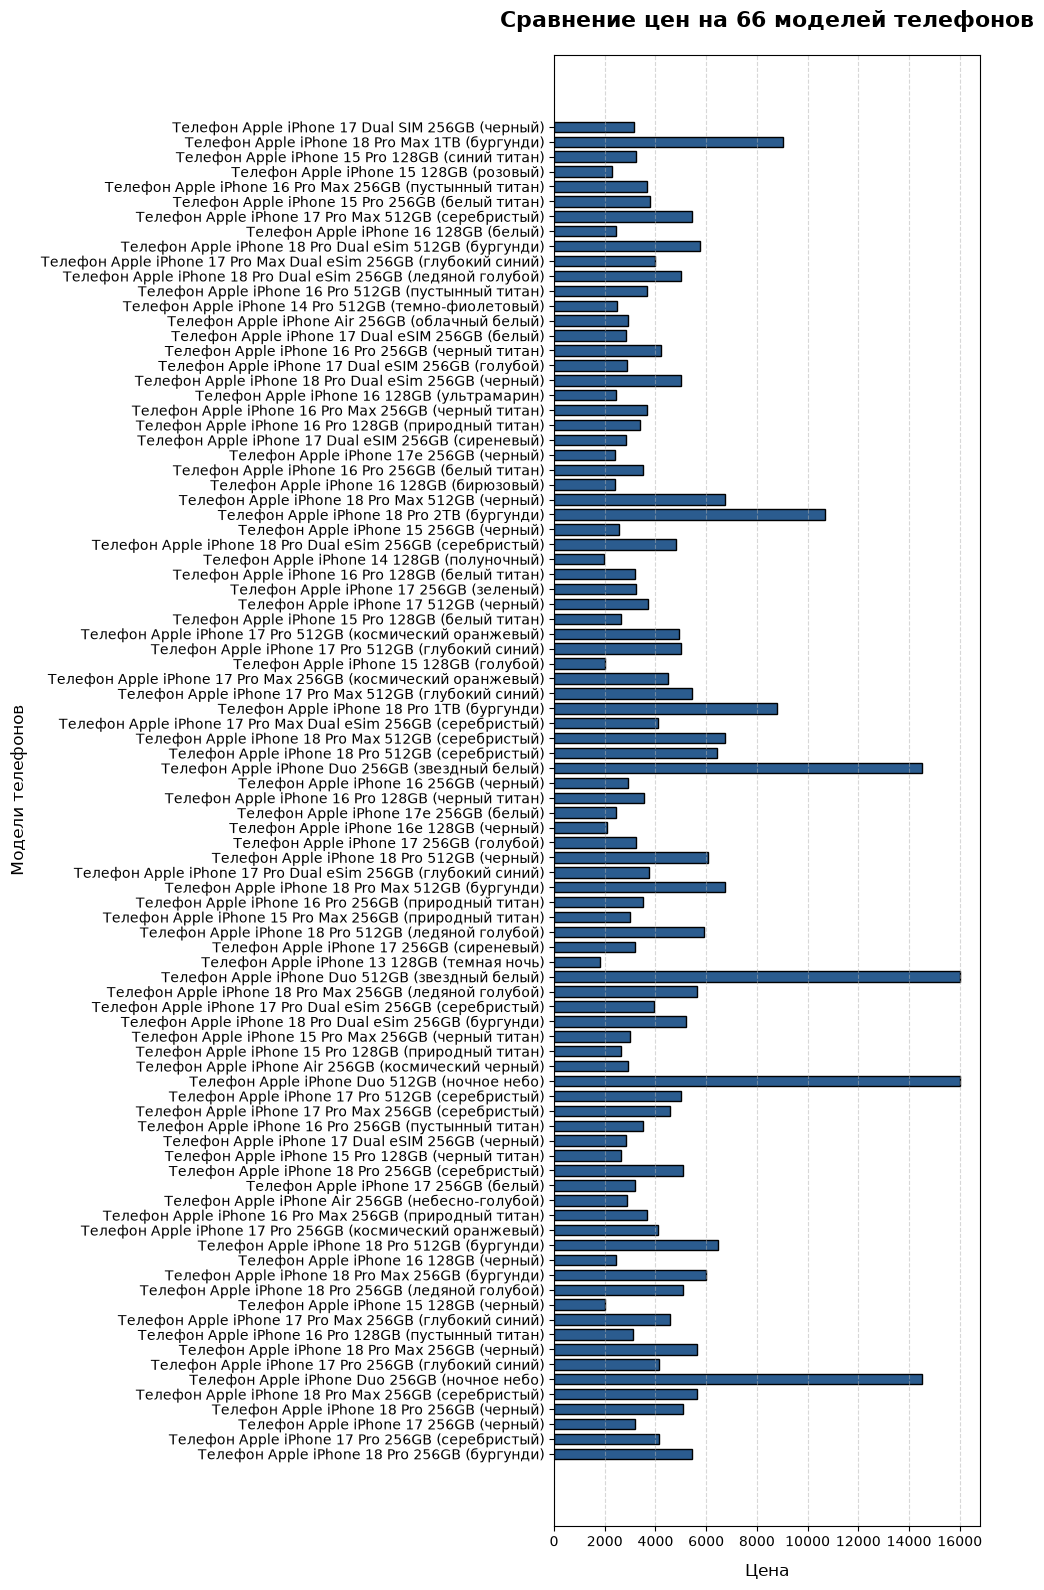

In [42]:
# 1. Загружаем ваши данные (ключи и значения)
lis_v = list(arr.keys())   
lis_k = list(arr.values()) 

# ХИТРОСТЬ 1: Принудительно превращаем названия моделей в ТЕКСТ (строки).
# Теперь Matplotlib поймет, что это подписи осей, а не координаты!
# Замените на lis_k = ..., если названия моделей лежат в ключах.
lis_v = [str(x) for x in lis_v] 

# ХИТРОСТЬ 2: Убеждаемся, что цены — это чистые числа.
lis_k = [int(''.join(char for char in str(x) if char.isdigit())) for x in lis_k]

fig, ax = plt.subplots(figsize=(10, 16)) 

# Строим график: текстовые модели (lis_v) пойдут по вертикали, 
# числовые цены (lis_k) зададут красивую длину синих полос.
bars = ax.barh(lis_v, lis_k, color='#2b5c8f', edgecolor='black', height=0.7)

ax.set_title('Сравнение цен на 66 моделей телефонов', fontsize=16, pad=20, fontweight='bold')
ax.set_xlabel('Цена', fontsize=12, labelpad=10)
ax.set_ylabel('Модели телефонов', fontsize=12, labelpad=10)

# Чистим сетку
ax.grid(axis='x', linestyle='--', alpha=0.5)

# Добавляем левый отступ, чтобы ваши номера моделей слева полностью влезли
plt.subplots_adjust(left=0.25) 

plt.tight_layout()
plt.show()


